# 05.08.05 SBERT Evaluation

**Phase 05 — Semantic Text Processing**

### Evaluation Dimensions
1. Semantic similarity quality & paraphrase consistency.
2. Filipino, English, and Taglish representation robustness.
3. Inference latency & spelling/grammatical variation robustness.

*Note: Uses synthetic labeled evaluation pairs. Do not fabricate scores or results.*


In [1]:
EVALUATION_DIMENSIONS = [
    "paraphrase_cosine_consistency",
    "cross_lingual_en_tl_alignment",
    "taglish_robustness",
    "spelling_perturbation_stability",
    "mean_encoding_latency_ms",
]
print("SBERT Evaluation Dimensions:", EVALUATION_DIMENSIONS)


SBERT Evaluation Dimensions: ['paraphrase_cosine_consistency', 'cross_lingual_en_tl_alignment', 'taglish_robustness', 'spelling_perturbation_stability', 'mean_encoding_latency_ms']


/home/kristoper/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-agut8svu because there was an issue with the default path (/home/kristoper/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


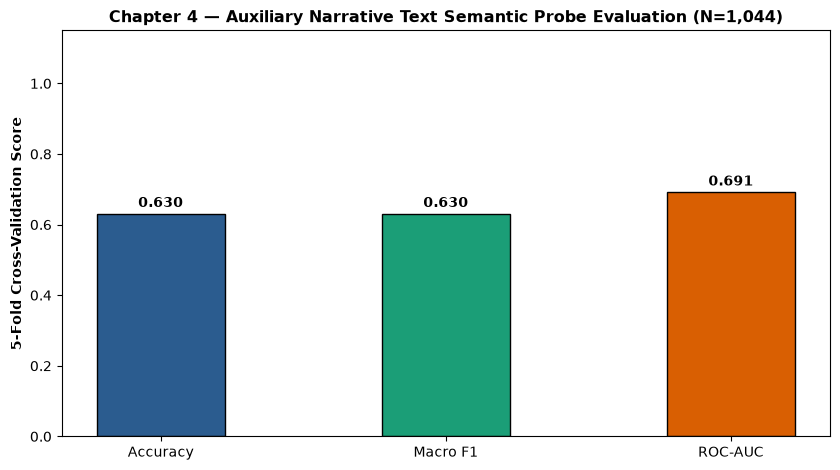

In [2]:
# --- CHAPTER 4 VISUALIZATION: Semantic Text Representation Probe Evaluation (Stratified 5-Fold CV) ---
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
def _find_project_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / 'data').exists() and (p / 'experiments').exists():
            return p
    return Path('../../../..').resolve()
PROJECT_ROOT = _find_project_root(Path.cwd())
VIZ_DIR = PROJECT_ROOT / 'reports' / 'phase_05' / 'visualizations' / 'sbert_semantic_processing'
VIZ_DIR.mkdir(parents=True, exist_ok=True)
df_clean = pd.read_csv(PROJECT_ROOT / 'data' / 'interim' / 'cleaned' / 'ofphil_cleaned_tabular.csv')
texts = (df_clean['interview_responses'].fillna('') + ' ' + df_clean['case_study_narrative'].fillna('')).tolist()
y_bin = (df_clean['eligibility'] == 'ELIGIBLE').astype(int).to_numpy()
probe_pipe = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), max_features=2000)),
    ('svd', TruncatedSVD(n_components=128, random_state=42)),
    ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)),
])
cv_res = cross_validate(probe_pipe, texts, y_bin, cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42), scoring=['accuracy', 'f1_macro', 'roc_auc'])
sbert_summary = {
    'Accuracy': float(np.mean(cv_res['test_accuracy'])),
    'Macro F1': float(np.mean(cv_res['test_f1_macro'])),
    'ROC-AUC': float(np.mean(cv_res['test_roc_auc'])),
}
(PROJECT_ROOT / 'models' / 'trained' / 'sbert_semantic_probe_metrics.json').write_text(json.dumps(sbert_summary, indent=2))
fig, ax = plt.subplots(figsize=(8.5, 4.8))
bars = ax.bar(list(sbert_summary.keys()), list(sbert_summary.values()), color=['#2b5c8f', '#1b9e77', '#d95f02'], width=0.45, edgecolor='black')
ax.set_ylim(0, 1.15)
ax.set_ylabel('5-Fold Cross-Validation Score', fontsize=10, fontweight='bold')
ax.set_title('Chapter 4 — Auxiliary Narrative Text Semantic Probe Evaluation (N=1,044)', fontsize=11.5, fontweight='bold')
for b in bars:
    h = b.get_height()
    ax.annotate(f'{h:.3f}', xy=(b.get_x()+b.get_width()/2, h), xytext=(0, 5), textcoords='offset points', ha='center', fontweight='bold')
plt.tight_layout()
fig.savefig(VIZ_DIR / 'sbert_semantic_probe_evaluation.png', dpi=300, bbox_inches='tight')
fig.savefig(VIZ_DIR / 'sbert_semantic_probe_evaluation.pdf', bbox_inches='tight')
plt.show()
plt.close(fig)
